In [1]:
# DHN_THV_3G_R_S_BASE.py
#
# Outputs:
#   archetypes/DHN_THV_3G_R_S_BASE/nodes.csv   — node table
#   archetypes/DHN_THV_3G_R_S_BASE/pipes.csv   — pipe table
#   archetypes/DHN_THV_3G_R_S_BASE/graph.png   — topology plot
#
# Usage:
#   python dhn_benchmark/networks/thv_radial.py

In [2]:
# ---------------------------------------------------------
# TOPOLOGY
# ---------------------------------------------------------

NODES = [
    # id        type           x      y
    ("src",    "source",       0,     0),

    ("a",      "junction",     0,   300),
    ("b",      "junction",   300,     0),
    ("c",      "junction",     0,   600),
    ("d",      "junction",   600,     0),

    ("sub1",   "substation", -150,  300),
    ("sub2",   "substation",  150,  300),

    ("sub3",   "substation",  300, -150),
    ("sub4",   "substation",  300,  150),

    ("sub5",   "substation", -150,  600),
    ("sub6",   "substation",  150,  600),
    ("sub7",   "substation",    0,  750),

    ("sub8",   "substation",  600,  150),
    ("sub9",   "substation",  600, -150),
    ("sub10",  "substation",  750,    0),
]

EDGES = [
    ("src", "a"),
    ("src", "b"),
    ("a",   "c"),
    ("b",   "d"),
    ("a",   "sub1"),
    ("a",   "sub2"),
    ("b",   "sub3"),
    ("b",   "sub4"),
    ("c",   "sub5"),
    ("c",   "sub6"),
    ("c",   "sub7"),
    ("d",   "sub8"),
    ("d",   "sub9"),
    ("d",   "sub10"),
]

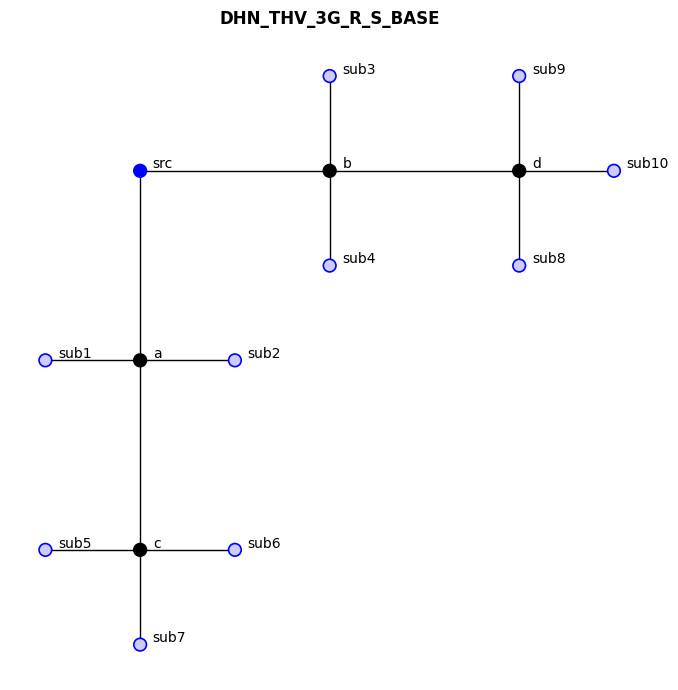

(<Figure size 700x700 with 1 Axes>,
 <Axes: title={'center': 'DHN_THV_3G_R_S_BASE'}>)

In [3]:
import sys
sys.path.insert(0, "../")

from dhn_benchmark.plotting import plot_topology
plot_topology(NODES, EDGES, title="DHN_THV_3G_R_S_BASE")

In [4]:
# ---------------------------------------------------------
# TOPOLOGY KPIs
# ---------------------------------------------------------
import networkx as nx

G = nx.Graph()
G.add_nodes_from([n[0] for n in NODES])
G.add_edges_from(EDGES)

N = len(NODES)
E = len(EDGES)
L = E - N + 1

degrees    = dict(G.degree())
avg_deg    = round(sum(degrees.values()) / N, 3)
max_deg    = max(degrees.values())
diameter   = nx.diameter(G)
avg_path   = round(nx.average_shortest_path_length(G), 3)
alpha      = round(L / max(2 * N - 5, 1), 4)

n_src = sum(1 for n in NODES if n[1] == "source")
n_jun = sum(1 for n in NODES if n[1] == "junction")
n_sub = sum(1 for n in NODES if n[1] == "substation")

KPIS = {
    "network_code"     : "DHN_THV_3G_R_S_BASE",
    "generation"       : "3G",
    "topology"         : "radial",
    "n_nodes"          : N,
    "n_edges"          : E,
    "n_loops"          : L,
    "n_sources"        : n_src,
    "n_junctions"      : n_jun,
    "n_substations"    : n_sub,
    "avg_degree"       : avg_deg,
    "max_degree"       : max_deg,
    "diameter_hops"    : diameter,
    "avg_path_hops"    : avg_path,
    "meshedness_alpha" : alpha,
}

# checks
assert L    == 0,  f"L={L}"
assert N    == 15, f"N={N}"
assert E    == 14, f"E={E}"
assert n_sub == 10, f"n_sub={n_sub}"

print("KPIs:")
for k, v in KPIS.items():
    print(f"  {k:<22} {v}")

KPIs:
  network_code           DHN_THV_3G_R_S_BASE
  generation             3G
  topology               radial
  n_nodes                15
  n_edges                14
  n_loops                0
  n_sources              1
  n_junctions            4
  n_substations          10
  avg_degree             1.867
  max_degree             4
  diameter_hops          6
  avg_path_hops          3.238
  meshedness_alpha       0.0


In [9]:
# ---------------------------------------------------------
# PIPE SIZING — DHN_THV_3G_R_S_BASE
# ---------------------------------------------------------

import math, sys, importlib
sys.path.insert(0, "../")

import dhn_benchmark.constants as co
import dhn_benchmark.demand_profile as dp
importlib.reload(co)
importlib.reload(dp)

from dhn_benchmark.constants  import GEN_OPERATING, PIPE_CATALOGUE
from dhn_benchmark.demand_profile import Q_PEAK_W

import networkx as nx

# --- operative parameters for 3G ---
gp       = GEN_OPERATING["3G"]
RHO      = gp["rho"]
CP       = gp["cp"]
DELTA_T  = gp["delta_T_nom"]
V_MAX    = gp["v_max"]
T_SUPPLY = gp["T_supply_nom"]
P_NOM    = gp["P_nom_bar"]

HEAT_LOSS_FACTOR = 1.05


G_dir = nx.DiGraph()
G_dir.add_edges_from(EDGES)

Q_node = {n[0]: Q_PEAK_W if n[1] == "substation" else 0.0
          for n in NODES}

def downstream_load(graph, from_node, to_node):
    reachable = nx.descendants(graph, to_node) | {to_node}
    return round(sum(Q_node.get(n, 0.0) for n in reachable) * HEAT_LOSS_FACTOR, 1)

def select_dn(Q_w):
    mdot = Q_w / (CP * DELTA_T)
    for dn, (di, do, s, dc) in sorted(PIPE_CATALOGUE.items()):
        A = math.pi * di**2 / 4.0
        v = mdot / (RHO * A)
        if v <= V_MAX:
            return dn, di, do, dc, s, round(mdot, 4), round(v, 3)
    dn, (di, do, s, dc) = sorted(PIPE_CATALOGUE.items())[-1]
    A = math.pi * di**2 / 4.0
    v = mdot / (RHO * A)
    return dn, di, do, dc, s, round(mdot, 4), round(v, 3)

# --- sizing ---
PIPE_SIZING = {}

print(f"{'pipe_id':<14} {'from':<8} {'to':<10} "
      f"{'mdot kg/s':>8} {'DN':>5} "
      f"{'d_i mm':>8} {'d_o mm':>8} {'v m/s':>7}")
print("-" * 85)

for u, v in EDGES:
    pid = f"{u}_{v}"
    Q   = downstream_load(G_dir, u, v)
    dn, di, do, dc, s, mdot, vel = select_dn(Q)
    PIPE_SIZING[pid] = {
        "from_node"      : u,
        "to_node"        : v,
        "Q_kW"           : round(Q / 1000, 1),
        "mdot_kgs"       : mdot,
        "DN_mm"          : dn,
        "d_inner_m"      : di,
        "d_outer_m"      : do,
        "d_casing_m"     : dc,
        "wall_m"         : s,
        "roughness_m"    : co.ROUGHNESS_STEEL,
        "lambda_PUR_WmK" : co.LAMBDA_PUR,
        "v_ms"           : vel,
    }
    print(f"{pid:<14} {u:<8} {v:<10} "
          f"{mdot:>8.4f} {dn:>5} "
          f"{di*1000:>8.1f} {do*1000:>8.1f} {vel:>7.3f}")

print("-" * 85)

print(f"  T_supply_nom   : {T_SUPPLY} °C")
print(f"  P_nom          : {P_NOM} bar")
print(f"  delta_T_nom    : {DELTA_T} K)")
print(f"  Q_substation   : demand_profile.csv")

pipe_id        from     to         mdot kg/s    DN   d_i mm   d_o mm   v m/s
-------------------------------------------------------------------------------------
src_a          src      a            7.3004    65     71.7     76.1   1.861
src_b          src      b            7.3004    65     71.7     76.1   1.861
a_c            a        c            4.3802    50     54.5     60.3   1.932
b_d            b        d            4.3802    50     54.5     60.3   1.932
a_sub1         a        sub1         1.4601    25     28.2     33.7   2.406
a_sub2         a        sub2         1.4601    25     28.2     33.7   2.406
b_sub3         b        sub3         1.4601    25     28.2     33.7   2.406
b_sub4         b        sub4         1.4601    25     28.2     33.7   2.406
c_sub5         c        sub5         1.4601    25     28.2     33.7   2.406
c_sub6         c        sub6         1.4601    25     28.2     33.7   2.406
c_sub7         c        sub7         1.4601    25     28.2     33.7   2.406
d

In [14]:
# ---------------------------------------------------------
# CSV EXPORT
# ---------------------------------------------------------
import csv, os

NETWORK_CODE = "DHN_THV_3G_R_S_BASE"

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
OUT_DIR   = os.path.join(REPO_ROOT, "data", NETWORK_CODE)
os.makedirs(OUT_DIR, exist_ok=True)

# ---- nodes.csv ----
with open(os.path.join(OUT_DIR, "nodes.csv"), "w", newline="") as f:
    w = csv.writer(f)
    w.writerow([
        "node_id", "node_type", "x_m", "y_m", "circuit",
        "Q_substations_W", "T_supply_set_degC", "delta_T_nom_K",
    ])
    for nid, ntype, x, y in NODES:
        # supply
        w.writerow([
            nid, ntype, x, y, "supply",
            "demand_profile.csv" if ntype == "substation" else "",
            T_SUPPLY             if ntype == "source"     else "",
            DELTA_T              if ntype == "substation" else "",
        ])
        # return — stesse 8 colonne
        rid = "src_r" if nid == "src" else nid + "_r"
        w.writerow([
            rid, ntype, x, y, "return",
            "demand_profile.csv" if ntype == "substation" else "",
            "",
            DELTA_T              if ntype == "substation" else "",
        ])

print(f"nodes.csv → {len(NODES)*2} rows")

# ---- pipes.csv ----
with open(os.path.join(OUT_DIR, "pipes.csv"), "w", newline="") as f:
    w = csv.writer(f)
    w.writerow([
        "pipe_id", "from_node", "to_node", "circuit",
        "mdot_kgs", "DN_mm",
        "d_inner_m", "d_outer_m", "d_casing_m", "wall_m",
        "roughness_m", "lambda_PUR_WmK", "v_ms",
    ])
    for pid, d in PIPE_SIZING.items():
        # supply
        w.writerow([
            pid, d["from_node"], d["to_node"], "supply",
            d["mdot_kgs"], d["DN_mm"],
            d["d_inner_m"], d["d_outer_m"], d["d_casing_m"], d["wall_m"],
            d["roughness_m"], d["lambda_PUR_WmK"], d["v_ms"],
        ])
        # return
        ur = "src_r" if d["from_node"] == "src" else d["from_node"] + "_r"
        vr = "src_r" if d["to_node"]   == "src" else d["to_node"]   + "_r"
        w.writerow([
            pid + "_r", vr, ur, "return",
            d["mdot_kgs"], d["DN_mm"],
            d["d_inner_m"], d["d_outer_m"], d["d_casing_m"], d["wall_m"],
            d["roughness_m"], d["lambda_PUR_WmK"], d["v_ms"],
        ])

print(f"pipes.csv → {len(PIPE_SIZING)*2} rows")
print(f"\nDone → {OUT_DIR}")

nodes.csv → 30 rows
pipes.csv → 28 rows

Done → C:\Users\sara.ferrero\PycharmProjects\dhn-benchamrk\dhn_benchmark\data\DHN_THV_3G_R_S_BASE
